# E3 · Modelos de MineTrac: ARIMA y clasificador

**Autores:** Carlos Alejandro Vizcaino Anguiano y Diego Reyes Natilla · Tecnológico Nacional de México campus Colima · Máquinas Centella S.A. de C.V.

Alcance: los 7 camiones (bitácora real). Aquí justificamos el ARIMA y comparamos los clasificadores; la API (`services/modelos`) usa exactamente estas funciones.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import sys; sys.path.insert(0,'..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from services.worker.analitica import serie_semanal, acf_pacf, adf
from services.modelos import modelos as m
b=pd.read_csv('../data/clean/mantenimiento.csv',encoding='utf-8-sig')
s=serie_semanal(b)
print(len(s),'semanas,',int(s.sum()),'intervenciones')

132 semanas, 251 intervenciones


## 1. Elegir (p, d, q)

La prueba ADF de la serie original da p = 0.015 (estacionaria al 5 %), pero la serie tiene una tendencia creciente y los residuos de los modelos con d = 0 quedan correlacionados. Por eso probamos d = 0 y d = 1 y comparamos AIC, BIC y la prueba de Ljung-Box de los residuos.

0.014695373091592032 3.5015000983376657e-22


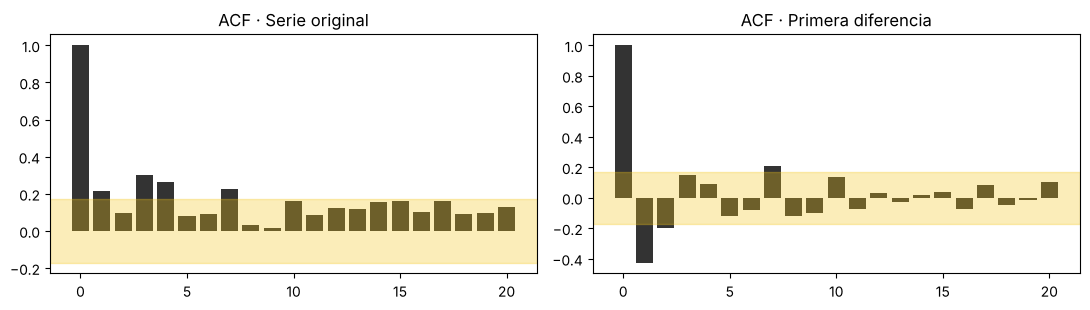

In [2]:
print(adf(s)['p_valor'], adf(s.diff().dropna())['p_valor'])
fig,ax=plt.subplots(1,2,figsize=(11,3.2))
for a,(x,t) in zip(ax,[(s,'Serie original'),(s.diff().dropna(),'Primera diferencia')]):
    r=acf_pacf(x,20); a.bar(range(21),r['acf'],color='#333'); a.axhspan(-r['banda'],r['banda'],color='#f5c518',alpha=.3); a.set_title('ACF · '+t)
plt.tight_layout(); plt.show()

In [3]:
t=m.buscar_arima(s); t.head(8).round(3)

,p,d,q,aic,bic,ljung_box_p,converge
0,2,1,3,522.671,539.922,0.822,False
1,0,1,1,523.690,529.441,0.114,True
2,3,1,1,523.724,538.100,0.760,True
3,3,1,2,524.416,541.667,0.832,True
4,3,1,3,524.472,544.599,0.867,False
5,3,0,1,524.688,541.985,0.871,True
6,0,1,2,525.383,534.008,0.121,True
7,3,0,0,525.434,539.848,0.707,True


**Decisión: ARIMA(0,1,1).** Tiene el segundo mejor AIC (523.7, a 1 punto del mejor), el mejor BIC entre los modelos que convergen y es el más simple. El ARIMA(2,1,3), que tiene el AIC más bajo, no converge. Después de una diferencia el ACF tiene su valor más fuerte y negativo en el rezago 1 (−0.43), el rezago 2 apenas supera la banda (−0.20) y de ahí en adelante se mantiene cerca de ella, que es el patrón de un MA(1): una sola media móvil basta. Con d = 1 los residuos no muestran autocorrelación (Ljung-Box p = 0.11), mientras que con ARIMA(1,0,0) sí (p = 0.005).

No usamos SARIMA: con 132 semanas solo caben dos ciclos y medio de 52 semanas (ver E2), así que un componente estacional anual no se puede estimar con confianza.

In [4]:
res=m.ajustar_arima(s); print(res.summary().tables[1])
lb=__import__('statsmodels.stats.diagnostic',fromlist=['x']).acorr_ljungbox(res.resid,lags=[10]); print(lb)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8775      0.040    -22.022      0.000      -0.956      -0.799
sigma2         3.0587      0.356      8.585      0.000       2.360       3.757
     lb_stat  lb_pvalue
10  15.51624   0.114343


## 2. Pronóstico a 7 y 30 días con banda al 95 %

La serie es semanal, así que 7 días = 1 semana y 30 días ≈ 4 semanas. Los conteos no pueden ser negativos, por eso el límite inferior se recorta en 0.

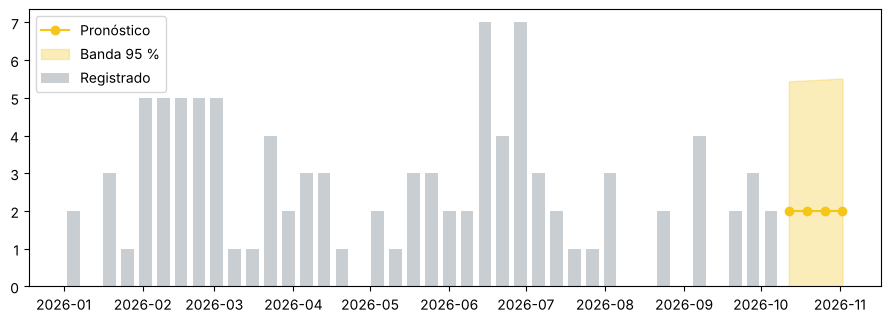

,semana,pronostico,inferior,superior
0,2026-10-12,2.01,0.0,5.44
1,2026-10-19,2.01,0.0,5.46
2,2026-10-26,2.01,0.0,5.49
3,2026-11-02,2.01,0.0,5.51


In [5]:
p=m.pronosticar(s,4)
fig,ax=plt.subplots(figsize=(11,3.6))
h=s.iloc[-40:]; ax.bar(h.index,h.values,width=5,color='#c9ced3',label='Registrado')
ax.plot(pd.to_datetime(p.semana),p.pronostico,'o-',color='#f5c518',label='Pronóstico')
ax.fill_between(pd.to_datetime(p.semana),p.inferior,p.superior,color='#f5c518',alpha=.3,label='Banda 95 %')
ax.legend(); plt.show(); p.round(2)

In [6]:
m.validar_arima(s)

{'semanas_prueba': 12,
 'mae_arima': 1.8755769437173673,
 'mae_ingenuo': 2.5,
 'cobertura_95': 1.0}

Revisión de sensatez (no es el backtesting completo del E4): ajustando con todo menos las últimas 12 semanas, el ARIMA tiene un error absoluto medio de 1.88 contra 2.50 del promedio de las últimas 4 semanas, y las 12 semanas reales caen dentro de la banda. La banda es ancha porque los conteos son pequeños y variables.

## 3. Clasificador: ¿el mismo sistema del mismo camión vuelve a registrarse en 30 días?

Usamos el dataset del Avance 1 (284 registros con objetivo conocido). El corte es temporal: 80 % más antiguo para entrenar y 20 % más reciente para probar, así nunca se usa el futuro para predecir el pasado. Se comparan Naive Bayes, KNN, SVM y un árbol, junto a dos referencias.

In [7]:
d=m.cargar_dataset('../data/clean/dataset_avance1.csv'); r=m.evaluar(d)
print({k:r[k] for k in ['n_entrenamiento','n_prueba','periodo_entrenamiento','periodo_prueba','positivos_entrenamiento','positivos_prueba']})
tab=pd.DataFrame({k:{a:v[a] for a in ['accuracy','precision','recall','f1','auc','f1_cv_media']} for k,v in r['modelos'].items()}).T
tab.round(3)

{'n_entrenamiento': 227, 'n_prueba': 57, 'periodo_entrenamiento': ['2023-08-04', '2026-04-14'], 'periodo_prueba': ['2026-04-14', '2026-09-07'], 'positivos_entrenamiento': 0.42731277533039647, 'positivos_prueba': 0.6666666666666666}


,accuracy,precision,recall,f1,auc,f1_cv_media
Referencia: clase más frecuente,0.333,0.000,0.000,0.000,0.500,0.000
"Referencia: siempre ""repite""",0.667,0.667,1.000,0.800,0.500,0.614
Naive Bayes,0.772,0.745,1.000,0.854,0.691,0.638
KNN (k=7),0.526,0.720,0.474,0.571,0.659,0.338
SVM (núcleo RBF),0.561,0.741,0.526,0.615,0.654,0.199
Árbol de decisión (profundidad 3),0.333,0.000,0.000,0.000,0.658,0.230


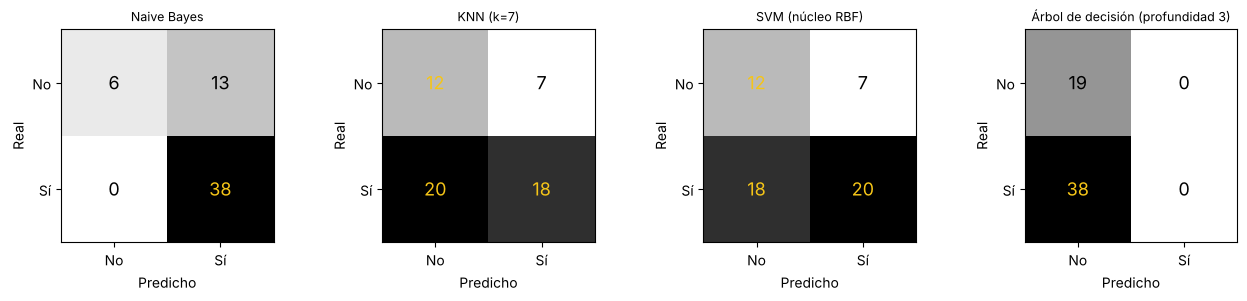

In [8]:
fig,ax=plt.subplots(1,4,figsize=(13,3))
for a,k in zip(ax,['Naive Bayes','KNN (k=7)','SVM (núcleo RBF)','Árbol de decisión (profundidad 3)']):
    cm=np.array(r['modelos'][k]['matriz_confusion']); a.imshow(cm,cmap='Greys'); a.set_title(k,fontsize=9)
    for i in range(2):
        for j in range(2): a.text(j,i,cm[i,j],ha='center',va='center',color='#f5c518' if cm[i,j]>cm.max()/2 else 'k',fontsize=13)
    a.set_xticks([0,1]); a.set_yticks([0,1]); a.set_xticklabels(['No','Sí']); a.set_yticklabels(['No','Sí']); a.set_xlabel('Predicho'); a.set_ylabel('Real')
plt.tight_layout(); plt.show()

**Lectura honesta.** Naive Bayes es el mejor (F1 = 0.85 en prueba, F1 medio de 0.64 en validación cruzada temporal), pero hay que verlo con cuidado: acierta todas las repeticiones (recall = 1.0) a costa de marcar casi todo como "repite" (solo 6 de 19 negativos bien clasificados). La referencia "siempre repite" ya obtiene F1 = 0.80, así que la ganancia real es pequeña, y el AUC (0.69) confirma una capacidad de separación modesta. El periodo de prueba tiene 67 % de repeticiones contra 42 % en el de entrenamiento: el taller tuvo más actividad reciente, y eso mueve las métricas. El árbol, con profundidad 3, termina prediciendo siempre "no repite" y no sirve.

En pocas palabras: con 284 registros y variables débiles, el clasificador sirve para ordenar casos por probabilidad, no para decidir solo. Con más historia y con horómetro por camión debería mejorar.